## Notes
I'm unsure on how they get index (idx) for the hpx map, and I think this should be the array index?<br>
Are we using pvalue as the cumprob? How do we get a p_value?

In [1]:
import math
import os
import sys
from base64 import b64encode
from collections import defaultdict
from datetime import datetime
from hashlib import blake2b
import json

import healpy as hp
import numpy as np
import requests
from astropy import units as u
from astropy.time import Time


#From cris
from astropy.table import QTable
from mhealpy import HealpixMap
import astropy_healpix as ah


sys.path.insert(1, '../')
from ic_visualization import plot_IC_alert

#plotting
from astropy.coordinates import SkyCoord
import matplotlib.pyplot as plt
import scipy.sparse 
from ligo.skymap.io.fits import read_sky_map

/Users/cristozilleruelo/opt/anaconda3/envs/AMPEL/lib/python3.12/site-packages/igwn_ligolw/lsctables.py:57: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  import lal


In [2]:
sys.path.insert(1, '/Users/cristozilleruelo/Ampel-HU-astro/ampel/contrib/hu/util/')
from AmpelHealpix import deres

In [3]:
alert_str = '{"$schema": "https://gcn.nasa.gov/schema/v6.1.0/gcn/notices/icecube/single_neutrino_alerts.schema.json", "mission": "IceCube", "instrument": "IC86", "messenger": "Neutrino", "pipeline": "Bronze Track Alert", "record_number": 1, "event_name": ["IceCube-260125A"], "id": ["141985_63695019"], "alert_datetime": "2026-01-25T10:10:28.0Z", "alert_type": "update", "alert_tense": "current", "alert_topology": "Track", "number_of_events": 1, "ra": 243.72, "dec": 6.69, "ra_dec_error": "0.8", "containment_probability": 0.9, "systematic_included": true, "healpix_url": "https://roc-2.icecube.wisc.edu/public/alerts/IceCube-260125A_skymap_probdensity_multiorder.fits.gz", "trigger_time": "2026-01-25T10:09:39.883Z", "nu_energy": 159.06, "p_astro": 0.3924, "far": "6.263e-08"}'
alert = json.loads(alert_str)

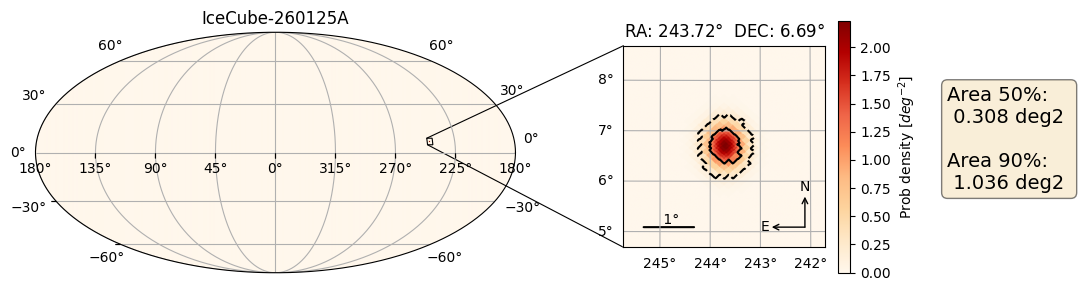

In [4]:
map_path = plot_IC_alert(alert['healpix_url'], ra_dec_err=float(alert['ra_dec_error']), r=2)

### process_map method

In [5]:
skymap = QTable.read(map_path)
headers = skymap.meta
prob_density = skymap['PROBDENSITY'].to_value(u.deg**-2)
m = HealpixMap(data=prob_density, uniq=skymap['UNIQ'], density=True)
pixel_areas = m.pixarea().to_value(u.deg**2) #* (180/np.pi)**2  # Convert steradians to deg^2

In [6]:
pixel_areas

array([1.34286983e+01, 1.34286983e+01, 1.34286983e+01, ...,
       3.27849080e-03, 3.27849080e-03, 3.27849080e-03], shape=(5556,))

In [7]:
idx = np.flipud( np.argsort(m.data) )
# sorted_credible_levels = np.cumsum( m.data[idx]* pixel_areas[idx] )

#From angela's notebook
skymap.sort("PROBDENSITY", reverse=True)
level, ipix = ah.uniq_to_level_ipix(skymap["UNIQ"])
nside = ah.level_to_nside(level)
pixel_area = ah.nside_to_pixel_area(nside)
prob = pixel_area * skymap["PROBDENSITY"]
sorted_credible_levels = np.cumsum(prob)

credible_levels = np.empty_like(sorted_credible_levels)
credible_levels[idx] = sorted_credible_levels


#50/90% region
skymap.sort("PROBDENSITY", reverse=True)
level, ipix = ah.uniq_to_level_ipix(skymap["UNIQ"])
nside = ah.level_to_nside(level)
pixel_area = ah.nside_to_pixel_area(nside)
prob = pixel_area * skymap["PROBDENSITY"]
cumprob = np.cumsum(prob)
lon, lat = ah.healpix_to_lonlat(ipix, nside=nside, order='nested')
i_50 = cumprob.searchsorted(0.5)
i_90 = cumprob.searchsorted(0.9)



In [8]:
# deres(nside[:i_90], ipix[:i_90])
masked_list = []
nsides = []
for nside_i in nside[:i_90]:
    if int(nside_i) not in nsides:
        nsides.append(int(nside_i))
for nside_i in nsides:
    masked_list.append({'nside': nside_i,
                       'pixels': []})
for nside_i, ipix_i in zip(nside[:i_90], ipix[:i_90]):
    for element in masked_list:
        if element['nside'] == int(nside_i):
            element['pixels'].append(int(ipix_i))

lon, lat = list(), list()
for element in masked_list:
    lon_i, lat_i = ah.healpix_to_lonlat(element['pixels'], nside=element['nside'], order='nested')
    lon.extend((lon_i/u.rad * u.rad).to('deg') / u.deg)
    lat.extend((lat_i/u.rad * u.rad).to('deg') / u.deg)


In [9]:
pvalue_limit=0.9

In [10]:
mask = np.zeros(len(credible_levels), dtype=int)
mask[credible_levels <= pvalue_limit] = 1

mask_list = mask.nonzero()[0].tolist()

In [12]:
debug = [{'nside': 1024, 'pixels': [1116637, 1116636, 1116630, 1117312, 1117228, 1117229, 1117227, 1116627, 1117322, 1116629, 1117313, 1117222, 1117226, 1117315, 1117316, 1117314, 1117318, 1117224, 1116628, 1116657, 1116631, 1116541, 1116661, 1116625, 1117223, 1117324, 1117344, 1116656, 1117320, 1117321, 1117242, 1117230, 1117225, 1117219, 1117328, 1117234, 1117233, 1117323, 1117345, 1117217, 1116658, 1116543, 1116626, 1117235, 1116639, 1116663, 1116635, 1116659, 1117240, 1117241, 1117221, 1116624, 1117325, 1116665, 1116638, 1116645, 1117319, 1117317, 1116540, 1116660, 1116666, 1116535, 1116667, 1116662, 1117199, 1117347, 1117326, 1117243, 1116633, 1116539, 1117218, 1116623, 1117329, 1117231, 1116668, 1116632, 1116647, 1116664, 1117348, 1116542, 1116671, 1116634, 1117195, 1117197, 1116670, 1116534, 1116669, 1117220, 1116621, 1117232, 1116538, 1117198, 1117216, 1117331, 1117336, 1116646, 1117330, 1117332, 1117346, 1117327, 1117338, 1117194, 1117353, 1117354, 1116620, 1117349, 1116644, 1117334, 1117352, 1116622, 1117196, 1117350, 1117356, 1116537, 1116533, 1116615, 1116531, 1116613, 1117360, 1117193, 1116527, 1116614, 1117337, 1116511, 1117351, 1117357, 1117335, 1117192, 1117355, 1117361, 1117333, 1117339, 1116525, 1116536, 1117358, 1116529, 1116509, 1116530, 1117359, 1116532, 1117363, 1116612, 1117362, 1116510, 1116508, 1116526, 1116528, 1116507, 1116519, 1116524, 1116506, 1116517, 1116518, 1116495, 1116505, 1116504, 1116516, 1116493, 1116494, 1116492]}, {'nside': 512, 'pixels': [279302, 279309, 279163, 279252, 279311, 279303, 279249, 279314, 279297, 279300, 279162, 279160, 279248, 279322, 279253, 279424, 279312, 279251, 279301, 279335, 279254, 279154, 278958, 279320, 279296, 279250, 279255, 278959, 279237, 279313, 278970, 279315, 278971, 279152, 279239, 279321, 279257, 279344, 279425, 279256, 279151, 278968, 279341, 278955, 279342, 279346, 279260, 278969, 279245, 278957, 279149, 279323, 279316, 279426, 278954, 279318, 279345, 278974, 279238, 279236, 278956, 279324, 279261, 279143, 279343, 279125, 278962, 278951, 279258, 279428, 279427, 279352, 279259, 279130, 279244, 279150, 278953, 279326, 278972, 278963, 279247, 279124, 279432, 279347, 279141, 279317, 279262, 279319, 278783, 278975, 278950, 278966, 278973, 279148, 279128, 279246, 279235, 278961, 279348, 279233, 279429, 278960, 279263, 279430, 278949, 279325, 279241, 279354, 279142, 279433, 279281, 279280, 278952, 278964, 278967, 279119, 279353, 279327, 279147, 279269, 279350, 279243, 279284, 279434, 278948, 279268, 278939, 278781, 279360, 279362, 279349, 279018, 278782, 278965, 279440, 278938, 279121, 279431, 279355, 279016, 279368, 279140, 279145, 279436, 279122, 278942, 279285, 279356, 278947, 279234, 278943, 279265, 279435, 279282, 279283, 279370, 279232, 279010, 279008, 278927, 279271, 279351, 279240, 278946, 279242, 279286, 279117, 279270, 278940, 279139, 279019, 279361, 278945, 279456, 279146, 278779, 278986, 278941, 279118, 279442, 279441, 279363, 279120, 279011, 278936, 279392, 279017, 278780, 279437, 278937, 279438, 279267, 279264, 279009, 278775, 279287, 279358, 279369, 279357, 279111, 279371, 278926, 278944, 278984, 279144, 279394, 278934, 279197, 279277, 278987, 279137, 279288, 279457, 279022, 278925, 279393, 278935, 278931, 279276, 279199, 279289, 279191, 279020, 279116, 279364, 279359, 279189, 279366, 279266, 279444, 279400, 279458, 279448, 279292, 279372, 278985, 278978, 279443, 278777, 279439, 279138, 278930, 279395, 279374, 279221, 279012, 278774, 279103, 279273, 278923, 279014, 278924, 279460, 279293, 279115, 278979, 278990, 279109, 278932, 278773, 279396, 279365, 279402, 278919, 279367, 278778, 279290, 279445, 279272, 278933, 279373, 279023, 278976, 279446, 279101, 279021, 278929, 279136, 279279, 279223, 278988, 279015, 279459, 279401, 279398, 279449, 279196, 278921, 279375, 279278, 279110, 279190, 279198, 279397, 279013, 278922, 279291, 278977, 279450, 278928, 279275, 278991, 278982, 278918, 278776, 279461, 279113, 279294, 279384, 279034, 278771, 279404, 279095, 278767, 279378, 279464, 279220, 279229, 279403, 279376, 279386, 278772, 279188, 279032, 278751, 279488, 278846, 278890, 279399, 278989, 279447, 279274, 279108, 279026, 279114, 278847, 279222, 278917, 279452, 279408, 279462, 280656, 279024, 278980, 279295, 278891, 279102, 279377, 278983, 280645, 279406, 279465, 279451, 280644, 279385, 278843, 279489, 279387, 278915, 279410, 279035, 279002, 279231, 279100, 279379, 279107, 278842, 279405, 279093, 279472, 280657, 280641, 279490, 279033, 279409, 279193, 278769, 278920, 279228, 278845, 278770, 279195, 278916, 279466, 279187, 278844, 278888, 278750, 278894, 278981, 279388, 279453, 278765, 280660, 279382, 279000, 279027, 279112, 279463, 279416, 279407, 280640, 279217, 279411, 278766, 279454, 279185, 278889, 279094, 279468, 279380, 279025, 279390, 278749, 278831, 279492, 279230, 278994, 278914, 279038, 279491, 279412, 279219, 279071, 279473, 280597, 279105, 279036, 278895, 280661, 279003, 278841, 278913, 279391, 280647, 280658, 279383, 279418, 279467, 279389, 279496, 279414, 279030, 279381, 278992, 279474, 280646, 279099, 279493, 279417, 279225, 279106, 278892, 279001, 279413, 279039]}]


`mask_list` should contain the indices of the pixels that passed the criteria. We will plot to see what p_value does what. 

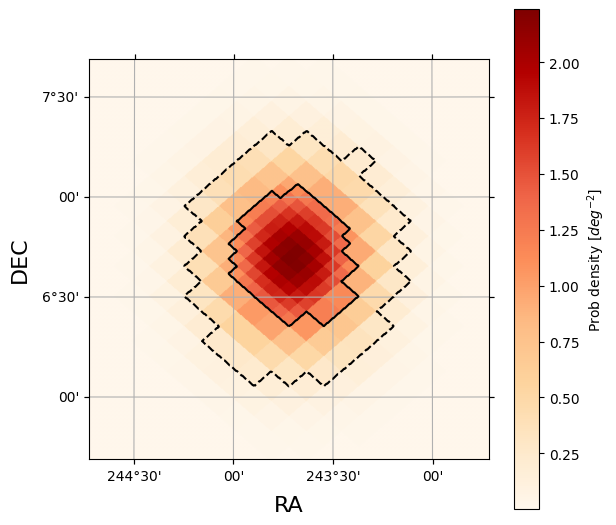

In [16]:
ra = float(headers['RA']) * u.deg
dec = float(headers['DEC']) * u.deg
center = SkyCoord(ra.to('rad'), dec.to('rad'), frame='icrs')

fig = plt.figure(figsize=(5, 5), dpi=100)
ax = plt.axes(
    [0.05, 0.05, 1, 1],
    projection=f'astro degrees zoom',
    center=center,
    radius=1*u.deg)


img = m.get_wcs_img(ax)#, coord = coord, rasterize = rasterize)
im = ax.imshow(img, cmap='OrRd')
c = plt.colorbar(im, label=r'Prob density [$deg^{-2}$]')


m_prob = HealpixMap(data=cumprob, uniq=skymap['UNIQ'], density=True)
img = m_prob.get_wcs_img(ax)#, coord = coord, rasterize = rasterize)
im = ax.contour(img, levels=[0.5, 0.9], colors=['black', 'black'], linestyles=['solid', 'dashed']) #nested=True,


#p_value_selection
# m_credible_levels = HealpixMap(data=credible_levels, uniq=skymap['UNIQ'], density=True)
# m_sort = HealpixMap(sorted_credible_levels, uniq=skymap['UNIQ'], density=True)
# img = m_sort.get_wcs_img(ax)#, coord = coord, rasterize = rasterize)
# im = ax.contour(img, levels=[0.5, 0.9], colors=['cyan'], linestyles=['dashed', 'solid']) #nested=True,
# # c = plt.colorbar(im, label=r'p_value')

# Combine pixels when possible
deresdict = deres(m.nside, mask_list)
healpix_regions = [
    {"nside": nside, "pixels": members} for nside, members in deresdict.items()
]
# ra_pixels, dec_pixels = m.pix2ang(healpix_regions[0]['pixels'] + healpix_regions[1]['pixels'], lonlat=True)
# ra_0, dec_0 = ah.healpix_to_lonlat(healpix_regions[0]['pixels'], healpix_regions[0]['nside'], order='nested')
# ra_1, dec_1 = ah.healpix_to_lonlat(healpix_regions[1]['pixels'], healpix_regions[1]['nside'], order='nested')
    

# sparse_matrix = scipy.sparse.csc_matrix((np.ones(len(ra)),(ra, dec)),(500, 500),dtype='float') 
# ax.imshow(sparse_matrix.toarray())

# ra_pixels = (np.concatenate([ra_0, ra_1]) /u.rad * u.rad).to('deg') / u.deg
# dec_pixels = (np.concatenate([dec_0, dec_1]) /u.rad * u.rad).to('deg') / u.deg
# ra_pixels = (lon[:i_90]/u.rad * u.rad).to('deg') / u.deg
# dec_pixels = (lat[:i_90]/u.rad * u.rad).to('deg') / u.deg

sel_pixels_lat = []
sel_pixels_lon = []
for dict_nside in debug:
    nside = dict_nside['nside']
    pixels = dict_nside['pixels']
    lon, lat = ah.healpix_to_lonlat(pixels, nside=nside, order='nested')
    sel_pixels_lat.extend(lat.to('deg') / u.deg)
    sel_pixels_lon.extend(lon.to('deg') / u.deg)

ax.scatter(sel_pixels_lon, sel_pixels_lat,c='green', marker='.', s=3, transform=ax.get_transform('world'), alpha=0.5, label='Queried pixels')

# ax.scatter(lon, lat,c='green', marker='.', s=3, transform=ax.get_transform('world'), alpha=0.5)
# ax.scatter(map_coords[0], map_coords[1],c='green', marker='s', transform=ax.get_transform('world'), alpha=0.5)


# m_combined = None
# for level in healpix_regions:    
#     m_i = HealpixMap(nside=level['nside'], scheme = 'nested', density = True)
#     m_i[level['pixels']] =  100
#     # m_i.plot()
#     if not m_combined:
#         m_combined = m_i
#         print('here')
#         m_combined.plot()
#     else:
#         m_combined += m_i
#         print('then here')
#         m_combined.plot()

# img = m_combined.get_wcs_img(ax)#, coord = coord, rasterize = rasterize)
# im = ax.contour(img, cmap='Greens')#, levels=[0.5, 1], linestyles=['solid', 'dashed']) #nested=True,
# c = plt.colorbar(im, label=r'selected pixels')

ax.grid()
ax.set_xlabel("RA", fontsize=16)
ax.set_ylabel("DEC", fontsize=16)
plt.show()


In [18]:
sel_pixels_lat

[<Quantity 12.40636063>,
 <Quantity 12.3681696>,
 <Quantity 12.32998415>,
 <Quantity 12.3681696>,
 <Quantity 12.3681696>,
 <Quantity 12.40636063>,
 <Quantity 12.3681696>,
 <Quantity 12.29180427>,
 <Quantity 12.4827595>,
 <Quantity 12.32998415>,
 <Quantity 12.40636063>,
 <Quantity 12.32998415>,
 <Quantity 12.32998415>,
 <Quantity 12.44455725>,
 <Quantity 12.44455725>,
 <Quantity 12.40636063>,
 <Quantity 12.4827595>,
 <Quantity 12.29180427>,
 <Quantity 12.29180427>,
 <Quantity 12.40636063>,
 <Quantity 12.3681696>,
 <Quantity 12.25362992>,
 <Quantity 12.4827595>,
 <Quantity 12.25362992>,
 <Quantity 12.3681696>,
 <Quantity 12.52096739>,
 <Quantity 12.52096739>,
 <Quantity 12.3681696>,
 <Quantity 12.44455725>,
 <Quantity 12.4827595>,
 <Quantity 12.4827595>,
 <Quantity 12.40636063>,
 <Quantity 12.32998415>,
 <Quantity 12.29180427>,
 <Quantity 12.52096739>,
 <Quantity 12.40636063>,
 <Quantity 12.40636063>,
 <Quantity 12.52096739>,
 <Quantity 12.55918094>,
 <Quantity 12.25362992>,
 <Quantity 1

In [15]:
# Combine pixels when possible
deresdict = deres(m.nside, mask_list)
healpix_regions = [
    {"nside": nside, "pixels": members} for nside, members in deresdict.items()
]

In [16]:
healpix_regions

[{'nside': 512, 'pixels': [1375]},
 {'nside': 1024, 'pixels': [5508, 5509, 5482, 5483, 5486, 5496, 5497, 5499]}]

In [17]:
ra, dec = ah.healpix_to_lonlat(healpix_regions[1]['pixels'], healpix_regions[1]['nside'], order='nested')
# m.pix2ang(healpix_regions[1]['pixels'], lonlat=True)
# print(ra.to('deg'))
# print(dec.to('deg'))
a = ra / u.rad * u.rad
a.to('deg')

<Quantity [49.65820312, 49.70214844, 49.96582031, 50.00976562, 50.05371094,
           50.18554687, 50.22949219, 50.18554688] deg>

In [18]:
dec

<Latitude [0.08016396, 0.08081711, 0.08343009, 0.08408342, 0.08473679,
           0.08539019, 0.08604363, 0.08669711] rad>

(<matplotlib.image.AxesImage at 0x11fffe150>, <Mollview: >)

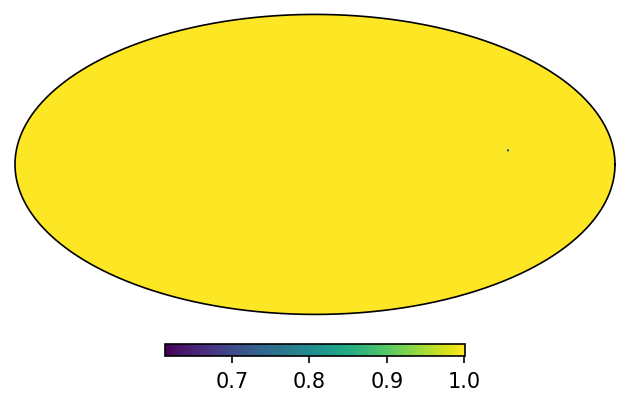

In [19]:
m_sort = HealpixMap(sorted_credible_levels, uniq=skymap['UNIQ'], density=True)
m_sort.plot()

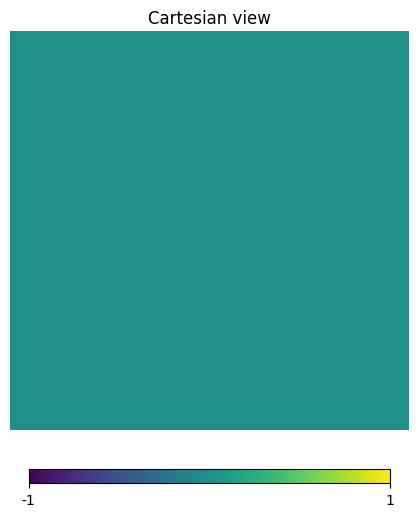

In [55]:
lonra = center.ra.degree + [-.1, .1]
latra = center.dec.degree + [-.1, .1]
hp.cartview(m_combined.data, nest =True, latra =latra, lonra =lonra)

In [56]:
from ligo.skymap.postprocess.util import find_greedy_credible_levels

In [64]:
skymap = QTable.read(map_path)
levels = find_greedy_credible_levels(skymap["PROBDENSITY"])

In [67]:
skymap.keys()

['UNIQ', 'PROBDENSITY']

In [106]:
hpx_map, header = read_sky_map(str(map_path))

# to be compatible with code relying on the 90% rectangle
# we parse accordingly from the header
# TODO:
#  The position values are taken from the header for now
#  because the position does not match for the example alert
#  between alert json and header!

ra = header["RA"]#, header["RA_ERR_MINUS"], header["RA_ERR_PLUS"]]
dec = header["DEC"]#, header["DEC_ERR_MINUS"], header["DEC_ERR_PLUS"]]

if not header["nest"]:
    print('here')
    hpx_map = hp.reorder(hpx_map, r2n=True)

skymap = np.array(hpx_map, dtype=[("PROB", float)])
skymap_header = header
prob_threshold = 0.9
# alert = alert
header['nest']

True

In [107]:
import mhealpy as mhp
map_nside = mhp.npix2nside(len(skymap))
print(map_nside)
output_nside = 1024
    # interpolate skymap to output nside if necessary
if output_nside is None:
    output_nside = map_nside
if output_nside != map_nside:
    print(
        f"Interpolating input skymap from nside {map_nside} to {output_nside}"
    )
    skymap = smooth_ud_grade(skymap, output_nside)
else:
    skymap = skymap
credible_levels = find_greedy_credible_levels(skymap["PROB"])

1024


(<matplotlib.image.AxesImage at 0x1204b1610>, <Mollview: >)

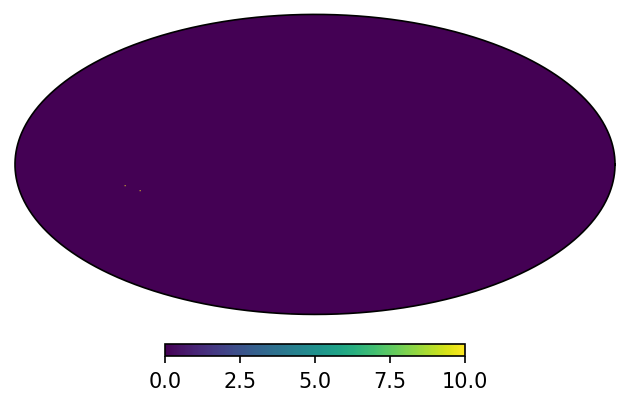

In [108]:
healpix_indices = np.where(credible_levels < prob_threshold)[0]
map_coords = hp.pix2ang(map_nside, healpix_indices, lonlat=True)
m_test = HealpixMap(nside=1024, scheme = 'nested')#, density = True)
m_test[healpix_indices] = 10
m_test.plot()

In [109]:
map_inside_threshold = skymap[healpix_indices]["PROB"]
map_inside_threshold /= np.sum(map_inside_threshold)

# calculate pixel area
total_pixel_area = hp.nside2pixarea(output_nside, degrees=True) * float(
    len(healpix_indices)
)
total_pixel_area

np.float64(1.03928158410914)

In [119]:
# skymap[healpix_indices]['PROB']
healpix_indices

array([5493460, 5493462, 5497555, 5497556, 5497557, 5497558, 5501649,
       5501651, 5501652, 5501653, 5501654, 5501655, 5505744, 5505745,
       5505746, 5505747, 5505748, 5505749, 5505750, 5505751, 5509841,
       5509842, 5509843, 5509844, 5509845, 5509846, 5509847, 5509848,
       5513937, 5513938, 5513939, 5513940, 5513941, 5513942, 5513943,
       5513944, 5518033, 5518034, 5518035, 5518036, 5518037, 5518038,
       5518039, 5518040, 5518041, 5522128, 5522129, 5522130, 5522131,
       5522132, 5522133, 5522134, 5522135, 5522136, 5522137, 5526224,
       5526225, 5526226, 5526227, 5526228, 5526229, 5526230, 5526231,
       5526232, 5526233, 5526234, 5530319, 5530320, 5530321, 5530322,
       5530323, 5530324, 5530325, 5530326, 5530327, 5530328, 5530329,
       5530330, 5534415, 5534416, 5534417, 5534418, 5534419, 5534420,
       5534421, 5534422, 5534423, 5534424, 5534425, 5534426, 5538510,
       5538511, 5538512, 5538513, 5538514, 5538515, 5538516, 5538517,
       5538518, 5538

In [129]:
# map_coords
i_90_pixel_indices
coord_i_90 = hp.pix2ang(1024, i_90_pixel_indices, lonlat=True)
coord_i_90

(array([280.23925781, 280.41503906, 279.97558594, 280.15136719,
        280.50292969, 278.04199219, 280.32714844, 278.30566406,
        280.94238281, 279.88769531, 281.03027344, 277.95410156,
        278.39355469, 280.67871094, 280.06347656, 295.53222656,
        277.86621094, 295.35644531, 296.05957031, 278.12988281,
        277.77832031, 281.20605469, 281.11816406, 278.92089844,
        276.98730469, 280.59082031, 293.42285156, 278.21777344,
        296.23535156, 279.09667969, 280.85449219, 276.81152344,
        295.62011719, 296.14746094, 277.33886719, 277.25097656,
        295.44433594, 277.60253906, 296.32324219, 288.76464844,
        276.89941406, 279.62402344, 280.76660156, 293.24707031,
        276.28417969, 278.83300781, 288.67675781, 303.79394531,
        276.72363281, 293.51074219, 277.69042969, 279.00878906,
        288.41308594, 296.41113281, 295.88378906, 303.88183594,
        277.07519531, 277.16308594, 276.19628906, 296.58691406,
        295.70800781, 279.79980469, 276.

In [116]:
deres(1024, healpix_indices)

{512: [np.int64(1396916),
  np.int64(1380532),
  np.int64(1396917),
  np.int64(1397940),
  np.int64(1381556),
  np.int64(1381557),
  np.int64(1397941),
  np.int64(1382580),
  np.int64(1398964),
  np.int64(1382581),
  np.int64(1398965),
  np.int64(1383604),
  np.int64(1399988),
  np.int64(1383605),
  np.int64(1399989),
  np.int64(1384628),
  np.int64(1401012),
  np.int64(1384629),
  np.int64(1401013),
  np.int64(1385652),
  np.int64(1385653),
  np.int64(1402037),
  np.int64(1395893),
  np.int64(1404085),
  np.int64(1376436),
  np.int64(1380533),
  np.int64(1389750),
  np.int64(1386676),
  np.int64(1386677),
  np.int64(1403061),
  np.int64(1387700),
  np.int64(1387701),
  np.int64(1388724),
  np.int64(1388725),
  np.int64(1405109),
  np.int64(1389748),
  np.int64(1389749),
  np.int64(1390772),
  np.int64(1390773),
  np.int64(1391796),
  np.int64(1375413),
  np.int64(1391797),
  np.int64(1392820),
  np.int64(1376437),
  np.int64(1392821),
  np.int64(1393844),
  np.int64(1377461),
  np.int

In [120]:
skymap.sort("PROBDENSITY", reverse=True)
level, ipix = ah.uniq_to_level_ipix(skymap["UNIQ"])


array([8094836, 8094838, 8094833, 8094835, 8094839, 8094811, 8094837,
       8094814, 8094844, 8094832, 8094845, 8094810, 8094815, 8094841,
       8094834, 8095010, 8094809, 8095008, 8095016, 8094812, 8094808,
       8094847, 8094846, 8094821, 8094799, 8094840, 8094986, 8094813,
       8095018, 8094823, 8094843, 8094797, 8095011, 8095017, 8094803,
       8094802, 8095009, 8094806, 8095019, 8094933, 8094798, 8094829,
       8094842, 8094984, 8094791, 8094820, 8094932, 8095104, 8094796,
       8094987, 8094807, 8094822, 8094929, 8095020, 8095014, 8095105,
       8094800, 8094801, 8094790, 8095022, 8095012, 8094831, 8094789,
       8094804, 8094985, 8094978, 8094935, 8094828, 8094928, 8095106,
       8094934, 8095108, 8094990, 8094788, 8094805, 8095107, 8095021,
       8094931, 8095015, 2023698, 8095023, 8094830, 8094979, 8095013,
       2023704, 8095110, 8094988, 8094976, 8095109, 8094930, 2023696,
       2018238, 8094991, 2018235, 8095111, 2023729, 2023778, 2023735,
       2018239, 8094